# Predicting Wine Quality Using Physicochemical Properties

---
embed-resources: true
echo: false
warning: false
message: false
---

## Introduction

Wine quality is traditionally evaluated by trained sommeliers through sensory analysis of aroma, taste, and texture. While expert evaluation can provide valuable insights, it is subjective and requires extensive training and experience. For a startup seeking to develop an "AI Sommelier," an automated method for estimating wine quality could reduce costs and improve consistency. This report investigates whether machine learning models can predict wine quality using objective physiochemical measurements of wine. These measurements include properties such as acidity, sugar content, sulfur dioxide levels, density, and alcohol concentration. Using historical wine data labeled with quality scores assigned by human evaluators, regression models are trained to predict wine quality based solely on these measurable features. The goal is to determine whether such models are accurate enough to assist in automated wine quality assessment.

## Methods

In [23]:
# imports
import pandas as pd
import numpy as np
from joblib import dump
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import confusion_matrix

### Data

In [24]:
# load data
wine_train = pd.read_csv(
    "wine-train.csv",
)
wine_test = pd.read_csv(
    "wine-test.csv",
)

The dataset contains physicochemical measurements for individual Portuguese “Vinho Verde” wines along with quality ratings assigned by human sensory evaluators. Each observation represents a single wine sample and includes chemical properties such as acidity levels, sulfur dioxide concentrations, density, pH, sulphates, alcohol content, and wine color. The training dataset is used to develop the predictive model, while the test dataset is reserved for evaluating model performance on unseen data. This separation helps ensure that the model’s performance reflects its ability to generalize to new wines rather than simply memorizing patterns in the training data.

| Variable | Type | Description |
|---|---|---|
| quality | int64 | The quality of the wine based on evaluation by a minimum of three sensory assessors using blind tasting. Scores range from 0 (very bad) to 10 (excellent). |
| color | object | The human-perceivable color of the wine: red or white. |
| fixed acidity | float64 | Grams of tartaric acid per cubic decimeter. |
| volatile acidity | float64 | Grams of acetic acid per cubic decimeter. |
| citric acid | float64 | Grams of citric acid per cubic decimeter. |
| residual sugar | float64 | Grams of residual sugar per cubic decimeter. |
| chlorides | float64 | Grams of sodium chloride per cubic decimeter. |
| free sulfur dioxide | float64 | Milligrams of free sulfur dioxide per cubic decimeter. |
| total sulfur dioxide | float64 | Milligrams of total sulfur dioxide per cubic decimeter. |
| density | float64 | Total density of the wine in grams per cubic centimeter. |
| pH | float64 | Acidity of the wine measured using the pH scale. |
| sulphates | float64 | Grams of potassium sulphate per cubic decimeter. |
| alcohol | float64 | Percent alcohol by volume. |

In [25]:
# summary statistics
wine_train.shape

(4157, 13)

The mean for "quality":

In [26]:
wine_train["quality"].mean()

np.float64(5.814289150829925)

The standard deviation for "quality":

In [27]:
wine_train["quality"].std()

np.float64(0.868748287046691)

My summary statsitics shows the dataset contains 4157 samples and 12 features. I calculated the mean and standard deviation of quality to summarize its basic characteristics. Below is a table of basic characteristics for every variable in the dataset:

In [28]:
wine_train.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,3987.000000,4157.000000,3958.000000,3917.000000,4157.000000,4133.000000,4157.000000,4157.000000,3921.000000,3934.000000,3961.000000,4157.000000
mean,7.220579,0.342403,0.316478,5.430406,0.056358,30.600048,115.221915,0.994710,3.218454,0.531784,10.502847,5.814289
std,1.295282,0.166465,0.145276,4.750618,0.035460,17.906396,56.581139,0.003004,0.159184,0.150914,1.189918,0.868748
min,3.800000,0.080000,0.000000,0.600000,0.012000,1.000000,6.000000,0.987110,2.740000,0.230000,8.000000,3.000000
25%,6.400000,0.230000,0.240000,1.800000,0.038000,17.000000,77.000000,0.992380,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.300000,0.310000,3.000000,0.048000,29.000000,118.000000,0.994900,3.210000,0.505000,10.300000,6.000000
75%,7.700000,0.410000,0.390000,8.100000,0.066000,41.000000,155.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.330000,1.230000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


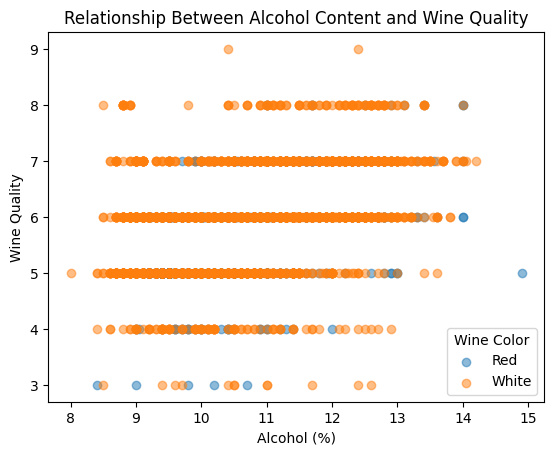

In [29]:
#| fig-cap: "Figure 1. Relationship Between Alcohol Content and Wine Quality by Wine Color"
# exploratory visualization
for color in ["red", "white"]:
    subset = wine_train[wine_train["color"] == color]

    plt.scatter(
        subset["alcohol"],
        subset["quality"],
        alpha=0.5,
        label=color.title(),
    )

plt.xlabel("Alcohol (%)")
plt.ylabel("Wine Quality")
plt.title("Relationship Between Alcohol Content and Wine Quality")
plt.legend(title="Wine Color")

plt.show()

### Models

In [30]:
# process data for ML
X_train = wine_train.drop("quality", axis=1)
y_train = wine_train["quality"]
X_test = wine_test.drop("quality", axis=1)
y_test = wine_test["quality"]

In [31]:
# train models
cat_cols = ["color"]
num_cols = [c for c in X_train.columns if c != "color"]

preprocess = ColumnTransformer(
    transformers=[
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), cat_cols),

        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), num_cols),
    ]
)

mod = Pipeline([
    ("preprocess", preprocess),
    ("clf", KNeighborsClassifier(n_neighbors=25, weights="distance")),
])
mod.fit(X_train, y_train)



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](7,)","[3,4,5,...,7,8,9]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['fixed acidity','volatile acidity','citric acid',...,'sulphates', 'alcohol','color']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

The wine quality prediction task was treated as a multi-class classification problem using physicochemical measurements of the wines as predictors. These predictors included acidity levels, sugar content, sulfur dioxide measurements, density, pH, sulphates, alcohol content, and wine color. Numeric features were imputed using the median and standardized, while the categorical feature (color) was imputed using the most frequent value and encoded using one-hot encoding. These preprocessing steps were combined using a column transformer and incorporated into a single scikit-learn pipeline to ensure consistent data processing during both training and prediction. A K-Nearest Neighbors (KNN) classifier with 25 neighbors and distance-based weighting was then trained on the training dataset and evaluated on the test dataset to assess how well the model predicts wine quality for new wines.

## Results

In [32]:
# report model metrics
y_pred = mod.predict(X_test)
test_mae = mean_absolute_error(y_test, y_pred)
print(f"Test MAE: {test_mae:.4f}")
test_acc = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {test_acc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Test MAE: 0.4327
Test Accuracy: 0.6154

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         7
           4       1.00      0.06      0.11        35
           5       0.65      0.70      0.67       318
           6       0.59      0.69      0.64       449
           7       0.58      0.49      0.53       190
           8       1.00      0.28      0.44        39
           9       0.00      0.00      0.00         2

    accuracy                           0.62      1040
   macro avg       0.55      0.32      0.34      1040
weighted avg       0.63      0.62      0.60      1040



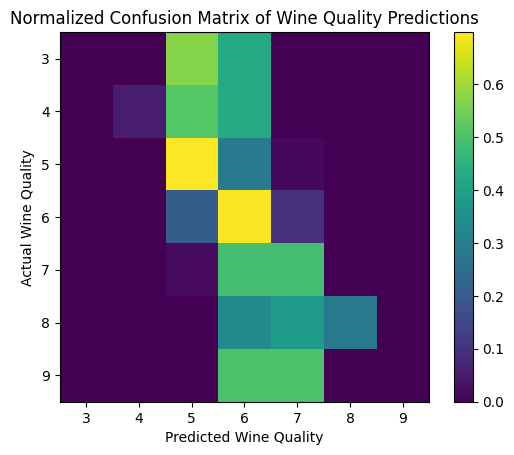

In [33]:
#| fig-cap: "Figure 2. Normalized Confusion Matrix for Wine Quality Predictions on the Test Dataset"
# summary figure
y_pred = mod.predict(X_test)

labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels, normalize="true")

plt.imshow(cm)
plt.colorbar()

plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)

plt.xlabel("Predicted Wine Quality")
plt.ylabel("Actual Wine Quality")
plt.title("Normalized Confusion Matrix of Wine Quality Predictions")

plt.show()

The selected K-Nearest Neighbors model was evaluated on the test dataset using the physicochemical properties of the wines as predictors. The model achieved a test mean absolute error (MAE) of 0.4327, indicating that predicted wine quality scores were typically less than half a point away from the true ratings on average.

The visualization in this section compares the predicted wine quality scores to the actual scores in the test data. Most predictions fall near the diagonal pattern, indicating that the model frequently predicts the correct quality level. When errors occur, they generally involve neighboring quality values, such as predicting a wine with quality 5 as 6 or vice versa. This pattern suggests that the model captures meaningful relationships between the measured chemical properties and perceived wine quality, while occasionally struggling to distinguish between wines with very similar characteristics.

Overall, the results indicate that the model provides reasonably accurate predictions of wine quality using only physicochemical measurements.

## Discussion

Based on the results presented above, I would recommend using this model in practice as a decision-support tool for the startup’s AI Sommelier system. The model demonstrates strong predictive performance, with an average prediction error of less than half a quality point. This suggests that the physicochemical measurements of wines contain useful information for estimating the quality ratings assigned by human evaluators.

One important benefit of this model is that it allows wine quality to be estimated quickly and consistently using objective chemical measurements. This could help reduce the time and cost associated with evaluating large numbers of wines while providing a standardized and repeatable method for preliminary quality assessment. In a real-world setting, the model could be used to automatically screen wines and identify those that are likely to have higher quality.

However, several limitations should also be considered. Wine quality is ultimately determined by sensory characteristics such as aroma, taste, and texture, which are not fully captured by the chemical measurements available in the dataset. Because of this, the model may sometimes assign similar quality scores to wines that differ in ways that human tasters can perceive.

The visualization shows that most prediction errors occur between neighboring quality levels. While these errors are relatively small, they could still have practical consequences. For example, predicting a lower-quality wine as higher quality could lead producers or distributors to overestimate its value, while predicting a higher-quality wine as lower quality could cause a strong product to be overlooked.

For these reasons, the model should not replace human sommeliers entirely. Instead, it would be most effective when used alongside human expertise. The system could provide an initial estimate of wine quality using measurable chemical features, and human evaluators could perform additional sensory assessments when necessary.

Overall, the model demonstrates that machine learning can successfully use physicochemical measurements to estimate wine quality. While it cannot fully replace expert tasting, it could serve as a valuable component of an automated wine evaluation system that improves efficiency and consistency in the wine industry.